## Problem 1 (3 pts)

Consider the following two models:
#### Personalized PageRank
This is the same model as standard PageRank, but every node has a certain "teleport" weight $t_i$. It models the preference of the user to restart the browsing with certain pages more than others (the probability of restarting at node $i$ is thus not necessarily uniform and is instead proportional to $\frac{t_i}{\sum t_j}$).
#### Friedkin-Johnsen Opinion Dynamics
$N$ agents are dynamically forming their opinions on a certain subject. Every agent has an innate level of conviction (prejudice) $s_i$ and a susceptibility coefficient $\lambda_i$ determining how much this agent is influenced by the opinions of others. Let $W$ be a given row-stochastic matrix of opinion weighting (determining the weighted average every agent applies to the opinions of others) and $\Lambda = diag\{\lambda_1, \ldots, \lambda_N\}$, then the dynamics of the opinion forming is described as
$$x_{t+1} = \Lambda W x_t + (I - \Lambda)s$$
with the steady state
$$(I - \Lambda W)x = (I - \Lambda)s.$$

## Task 1
Describe how Personalized PageRank can be considered a special case of the FJ model.

*your explanation here*

## Task 2
We shall now use the FJ model as a part of a more complex dynamics that we'll call *opinion crystallization*. Suppose that after the system reaches a stationary state $x$, it becomes the new baseline $s$. However, agent 1 is designated an *opinion leader* of the positive party and sticks to their original innate opinion $s^*_1$; with time, their susceptibility to opinions of others is decaying towards zero. Positive party's members pay significant attention to the leader.

*You can model different other political situations by altering the initialization of $W$ and sweeping $\lambda$ and $s$.*

Below is a brute-force implementation of the parameterized crystallization model assuming a bipartisan interaction matrix $W$ and initial convictions being polarized across the two parties.

Your task will be to avoid the costly $\Omega(n^3)$ matrix inversion at each step by observing that the inverted matrix only differs in a rank-one term (i.e., the difference between subsequent matrices to be inverted can be represented as $u^T v$ for some vectors $u$ and $v$) and applying the [Sherman-Morrison formula](https://en.wikipedia.org/wiki/Sherman%E2%80%93Morrison_formula). Please keep the brute-force implementation and compare the results numerically. What is the time complexity of your approach? Pick a larger $N$ and measure the practical speedup.

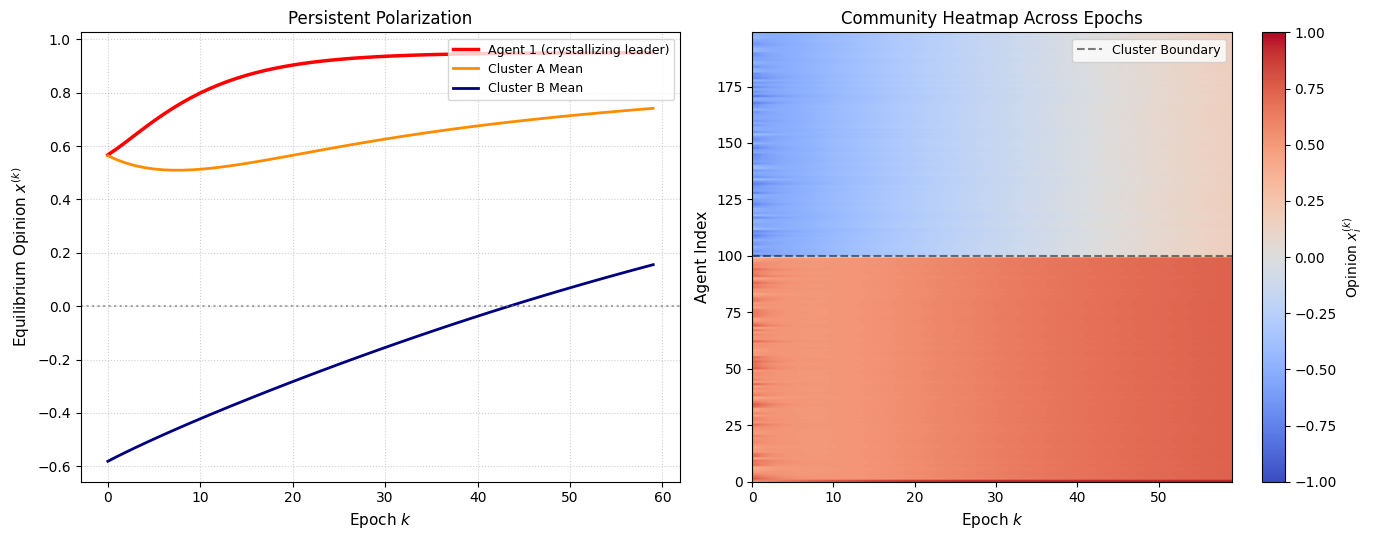

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Setup Polarized Network & Parameters
# -------------------------------------------------------------
np.random.seed(42)
n = 200
assert n % 2 == 0, "For simplicity, parties are assumed to be of the same size"
half = n // 2
T_epochs = 60

# Split into two clusters: 0..half (positive), half..n (negative)
s_0 = np.zeros((n, 1))
s_0[:half] = np.random.uniform(0.3, 0.9, size=(half, 1))
s_0[half:] = np.random.uniform(-0.9, -0.3, size=(half, 1))

# Agent 1 starts as an extreme positive leader
sticky_s1 = 0.95  # Agent 1 retains this core ideological anchor
s_0[0, 0] = sticky_s1

# Susceptibilities: base values for all agents, decay schedule for Agent 1
lambdas_base = np.random.uniform(0.3, 0.7, size=n)
gamma_decay = 0.90
lambda_1_history = [0.95 * (gamma_decay ** k) for k in range(T_epochs)]

# -------------------------------------------------------------
# 2. Block-Structured Interaction Matrix (Echo Chambers)
# -------------------------------------------------------------
raw_W = np.zeros((n, n))

# Strong intra-cluster ties
raw_W[:half, :half] = np.random.uniform(0.1, 0.5, size=(half, half))
raw_W[half:, half:] = np.random.uniform(0.1, 0.5, size=(half, half))

# Weak cross-cluster bridge ties
raw_W[:half, half:] = np.random.uniform(0.001, 0.01, size=(half, half))
raw_W[half:, :half] = np.random.uniform(0.001, 0.01, size=(half, half))

raw_W[1:half, 0] = 2.0  # Leader's party members pay heavy direct attention to leader (Agent 1)

np.fill_diagonal(raw_W, 0.0)
W = raw_W / raw_W.sum(axis=1, keepdims=True)  # Row stochasticity

I = np.eye(n)

# -------------------------------------------------------------
# 3. Brute-force simulation: Direct inversion on each epoch
# -------------------------------------------------------------
s_current = s_0.copy()
opinion_history = np.zeros((n, T_epochs))

for k in range(T_epochs):
    # Update Agent 1's susceptibility for the current epoch
    l1 = lambda_1_history[k]
    lambdas = lambdas_base.copy()
    lambdas[0] = l1
    Lambda = np.diag(lambdas)
    
    # Enforce sticky conviction for Agent 1
    s_current[0, 0] = sticky_s1
    
    # Assemble Friedkin-Johnsen linear system: (I - Lambda * W) x = (I - Lambda) s
    A = I - Lambda @ W
    b = (I - Lambda) @ s_current
    
    # Brute-force solve via explicit matrix inversion: O(n^3) per epoch
    A_inv = np.linalg.inv(A)
    x_k = A_inv @ b
    
    opinion_history[:, k] = x_k.ravel()
    
    # Next iteration update: peers assimilate previous consensus (Agent 1 will have it reset)
    s_current = x_k.copy()

# -------------------------------------------------------------
# 4. Visualization
# -------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
epochs = np.arange(T_epochs)

# Plot 1: Representative Trajectories
ax1.plot(epochs, opinion_history[0, :], "r-", linewidth=2.5, label="Agent 1 (crystallizing leader)")
ax1.plot(epochs, np.mean(opinion_history[:half, :], axis=0), "darkorange", linewidth=2, label="Cluster A Mean")
ax1.plot(epochs, np.mean(opinion_history[half:, :], axis=0), "navy", linewidth=2, label="Cluster B Mean")

ax1.axhline(0, color="gray", linestyle=":", alpha=0.7)
ax1.set_xlabel("Epoch $k$", fontsize=11)
ax1.set_ylabel("Equilibrium Opinion $x^{(k)}$", fontsize=11)
ax1.set_title("Persistent Polarization", fontsize=12)
ax1.legend(loc="upper right", fontsize=9)
ax1.grid(True, linestyle=":", alpha=0.6)

# Plot 2: Heatmap showing distinct cluster evolution
im = ax2.imshow(
    opinion_history,
    aspect="auto",
    origin="lower",
    cmap="coolwarm",
    extent=[0, T_epochs - 1, 0, n-1],
    vmin=-1.0,
    vmax=1.0
)
plt.colorbar(im, ax=ax2, label=r"Opinion $x_i^{(k)}$")
ax2.axhline(100, color="black", linestyle="--", alpha=0.5, label="Cluster Boundary")
ax2.set_title("Community Heatmap Across Epochs", fontsize=12)
ax2.set_xlabel("Epoch $k$", fontsize=11)
ax2.set_ylabel("Agent Index", fontsize=11)
ax2.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

*please don't forget to include your report*